### 🧪 Task 2: Histograms & Shapes of Distributions

**Title & Scenario:** You are analyzing the physical measurements of different flower species to build a classifier. You need to understand the underlying shape of your features to see if they follow a normal distribution or if they require transformation.
**Learning Objectives:** Creating histograms with multiple bin sizes, identifying distribution shapes (symmetric, right-skewed, left-skewed, bimodal), and calculating skewness.
**ML Connection:** Many ML algorithms (Linear/Logistic Regression, K-Means) assume features are roughly symmetric. Detecting skew guides whether you should apply log or Box-Cox transforms during your preprocessing pipeline.
**Step-by-Step Analytical Instructions:**

1. Load the Iris dataset using Seaborn.
2. Using Matplotlib, plot a 2x2 grid of histograms for all 4 numeric features (sepal_length, sepal_width, petal_length, petal_width). Use 10 bins for each.
3. Focus on the 'petal_length' column. Create a single figure with three overlapping histograms for this feature, using 5, 15, and 30 bins respectively. Use different colors and transparency so they overlay clearly.
4. Visually classify the shape of 'petal_length'. Is it symmetric, skewed, or bimodal?
5. Programmatically calculate and print the skewness score for all 4 features using Pandas.
   **Expected Output/Visualization:** A 2x2 grid of histograms. A single overlay plot showing three different bin configurations for petal length. A printed text output of 4 skewness numbers.
   **Key Takeaway:** Histograms reveal **shape**, but shape depends heavily on bin choice. The 'petal_length' feature is **bimodal**—a signal that the data contains distinct sub-populations (different species), which is highly informative for clustering tasks.

---

In [2]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

### 1st Step

In [3]:
df = sns.load_dataset('iris')

In [4]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


2. Using Matplotlib, plot a 2x2 grid of histograms for all 4 numeric features (sepal_length, sepal_width, petal_length, petal_width). Use 10 bins for each.


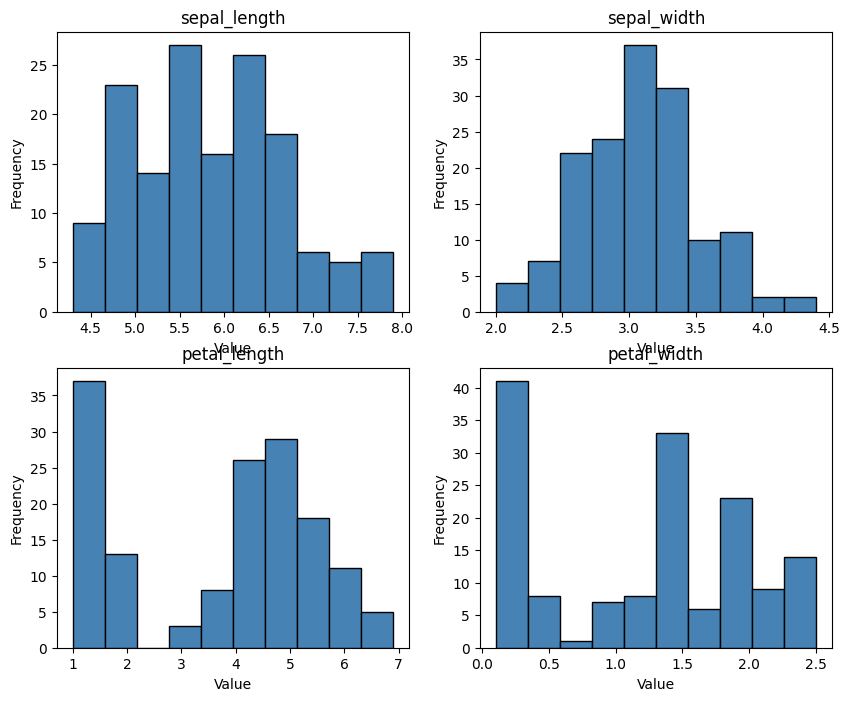

In [5]:
fig,axes = plt.subplots(nrows=2,ncols=2,figsize=(10,8))
axes = axes.flatten()
for ax, column in zip(axes, df.columns):
    ax.hist(df[column], bins=10, color="steelblue", edgecolor="black")
    ax.set_title(column)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    

### 3. Focus on the 'petal_length' column. Create a single figure with three overlapping histograms for this feature, using 5, 15, and 30 bins respectively. Use different colors and transparency so they overlay clearly.


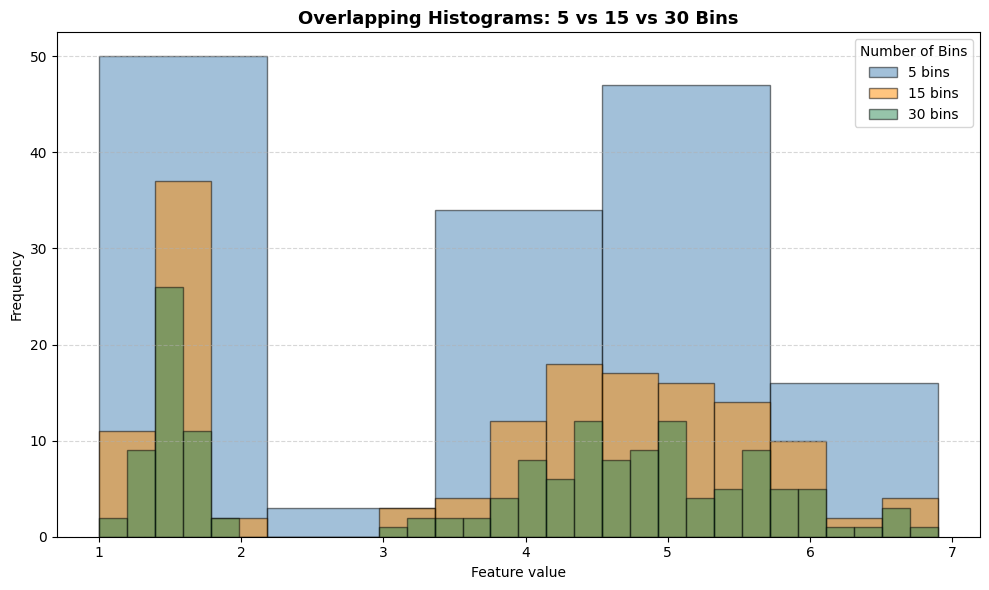

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(df['petal_length'], bins=5,  color="steelblue",   alpha=0.5, edgecolor="black", label="5 bins")
ax.hist(df['petal_length'], bins=15, color="darkorange",  alpha=0.5, edgecolor="black", label="15 bins")
ax.hist(df['petal_length'], bins=30, color="seagreen",    alpha=0.5, edgecolor="black", label="30 bins")

ax.legend(title='Number of Bins')
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_title("Overlapping Histograms: 5 vs 15 vs 30 Bins", fontsize=13, fontweight="bold")
ax.set_xlabel("Feature value")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

4. Visually classify the shape of 'petal_length'. Is it symmetric, skewed, or bimodal?


### I think it is quite symmetric on the right, starting from values around 3. However, there is a gap between 2 and 3. Additionally, for the bin from 1 to 2, the histogram is right-skewed.

5. Programmatically calculate and print the skewness score for all 4 features using Pandas.
   **Expected Output/Visualization:** A 2x2 grid of histograms. A single overlay plot showing three different bin configurations for petal length. A printed text output of 4 skewness numbers.
   **Key Takeaway:** Histograms reveal **shape**, but shape depends heavily on bin choice. The 'petal_length' feature is **bimodal**—a signal that the data contains distinct sub-populations (different species), which is highly informative for clustering tasks.


In [7]:
df['petal_length'].skew(False)

-0.27488417975101276

In [8]:
df['petal_width'].skew(False)

-0.10296674764898116

In [9]:
df['sepal_length'].skew(False)

0.3149109566369728

In [10]:
df['sepal_width'].skew(False)

0.31896566471359966

In [11]:
df.select_dtypes(include='number').skew()

sepal_length    0.314911
sepal_width     0.318966
petal_length   -0.274884
petal_width    -0.102967
dtype: float64